# Random Phase Approximation: W4-11RE dataset
**Author:** Egor Trushin  
**Date created:** 14/02/2025  
**Last modified:** 14/08/2025

W4-11RE dataset was introduced in:
> J.T. Margraf, D.S. Ranasinghe, and R.J. Bartlett. Automatic generation of reaction energy databases from highly accurate atomization energy benchmark sets - Phys. Chem. Chem. Phys. 19, 9798 (2017). https://doi.org/10.1039/C7CP00757D

The presented calculations partially repeat those from
> E. Trushin, A. Thierbach, A. Görling. Towards chemical accuracy at low computational cost: Density-functional theory with $\sigma$-functionals for the correlation energy - J. Chem. Phys. 154 (2021) 014104. https://doi.org/10.1063/5.0026849

In [1]:
import json
import os
import pyscf
import numpy as np
from pyscf import gto, dft
from pyscf.gw.rpa import RPA
from pyscf.gw.urpa import URPA
from tqdm import tqdm
from sets import W4_11, W4_11RE

import matplotlib.pyplot as plt
from matplotlib import rcParams
rcParams['font.family'] = 'sans-serif'
plt.rcParams['axes.unicode_minus'] = False

import warnings
warnings.filterwarnings('ignore')

In [2]:
if not os.path.exists("json"):
    os.makedirs("json")

In [3]:
print("PySCF version:", pyscf.__version__)

PySCF version: 2.10.0


## W4-11RE dataset

In [4]:
def atom_input(charges, xyz):
    """Construct input for mol.atom from charges and xyz."""
    atom_input_ = []
    for i in range(len(charges)):
        atom_input_.append([charges[i], tuple(xyz[i])])
    return atom_input_

In [5]:
def calc_one_system(atoms, coords, charge, spin, basis, xc):
    """Perform calculation for given system, basis and xc-functional."""
    mol = gto.Mole()
    mol.verbose = 0
    mol.atom = atom_input(atoms, coords)
    mol.basis = basis
    mol.charge = charge
    mol.spin = spin
    mol.build()

    if spin == 0:
        mf = dft.RKS(mol, xc=xc).density_fit().run()
        rpa = RPA(mf)
        rpa.kernel(nw=50, x0=2.5)
    else:
        mf = dft.UKS(mol, xc=xc).density_fit().run()
        rpa = URPA(mf)
        rpa.kernel(nw=50, x0=2.5)

    return float(mf.e_tot), float(rpa.e_tot)

In [6]:
def eval_ds(reactions, etot):
    """Evaluate dataset."""
    k = 0
    e_calc = np.zeros(len(reactions))
    e_ref = np.zeros(len(reactions))
    for i, _ in enumerate(reactions):
        ec = 0.0
        for j in range(len(reactions[i]["stoichiometry"])):
            ec += reactions[i]["stoichiometry"][j] * etot[reactions[i]["systems"][j]]
        e_calc[k] = ec * 627.50960803059
        e_ref[k] = reactions[i]["reference"]
        k += 1
    mae_all = np.mean(abs(e_calc - e_ref))
    return mae_all, e_calc, e_ref

In [7]:
def delete_systems_from_reactions(reactions, systems2remove):
    """Remove all reactions which contains given systems."""
    rs = []
    for r in reactions:
        nottoremove = True
        for s in r["systems"]:
            if s in systems2remove:
                nottoremove = False
        if nottoremove:
            rs.append(r)
    return rs

In [8]:
def plot_dev_histogram(e_rpa, e_dft, e_ref, mae_rpa, mae_dft, xc, max_range):
    """Plot histogram for deviations from reference reaction energies - PBE/PBE0 vs RPA@PBE/RPA@PBE0."""
    fig, ax = plt.subplots(1, 1, figsize=(5.5,4))

    ydft = e_dft - e_ref
    ax.hist(ydft, 64, color='orangered', range=(-max_range, max_range), alpha=0.5, label=f'{xc}')
    ax.hist(ydft, 64, histtype = 'step', color='k', lw = 1.0, range=(-max_range, max_range), alpha=1.0)

    yrpa = e_rpa - e_ref
    ax.hist(yrpa, 64, color='dodgerblue',range=(-max_range, max_range), alpha=0.5, label=f'RPA@{xc}')
    ax.hist(yrpa, 64, histtype = 'step', color='k' ,range=(-max_range, max_range), lw = 1.0, alpha=1.0)

    ax.set_ylabel('Count', fontsize=12)
    ax.set_xlabel('Deviation', fontsize=12)

    ax.set_xlim(-max_range-0.1, max_range+0.1)

    ax.legend(loc=1,frameon=False, fontsize=12)

    plt.text(0.01, 0.94, f"MAE[{xc}]={mae_dft:.2f}", fontsize=12, weight="medium", transform=ax.transAxes)
    plt.text(0.01, 0.88, f"MAE[RPA@{xc}]={mae_rpa:.2f}", fontsize=12, weight="medium", transform=ax.transAxes)

    plt.tight_layout()
    plt.show()

### PBE and RPA@PBE

In [9]:
BASIS_T = {"H":  "aug-cc-pVTZ",
           "Be": "aug-cc-pVTZ",
           "B":  "aug-cc-pwCVTZ",
           "C":  "aug-cc-pwCVTZ",
           "N":  "aug-cc-pwCVTZ",
           "O":  "aug-cc-pwCVTZ",
           "F":  "aug-cc-pwCVTZ",
           "Al": "aug-cc-pwCVTZ",
           "Si": "aug-cc-pwCVTZ",
           "P":  "aug-cc-pwCVTZ",
           "S":  "aug-cc-pwCVTZ",
           "Cl": "aug-cc-pwCVTZ"}

In [10]:
reactions = delete_systems_from_reactions(W4_11RE.reactions, ["c2"])

#### aug-cc-pwCVTZ orbital basis set

In [11]:
if os.path.isfile("json/W4-11_PBE_T.json"):
    print('Reading results from W4-11_PBE_T.json')
    with open("json/W4-11_PBE_T.json", 'r') as file_obj:
        (etot_pbe, etot_rpa) = json.load(file_obj)
else:
    etot_pbe = dict()
    etot_rpa = dict()
    pbar = tqdm(sorted(W4_11.systems))
    for system in pbar:
        e_pbe, e_rpa = calc_one_system(W4_11.systems[system]["atoms"],
                                       W4_11.systems[system]["coords"],
                                       W4_11.systems[system]["charge"],
                                       W4_11.systems[system]["spin"],
                                       BASIS_T,
                                       "PBE")
        etot_pbe[system] = e_pbe
        etot_rpa[system] = e_rpa
    with open('json/W4-11_PBE_T.json', 'w', encoding='utf-8') as file_obj:
        json.dump((etot_pbe, etot_rpa), file_obj, ensure_ascii=False, indent=4)

Reading results from W4-11_PBE_T.json


In [12]:
mae_pbe, re_pbe, re_ref = eval_ds(reactions, etot_pbe)
mae_rpa, re_rpa, re_ref = eval_ds(reactions, etot_rpa)

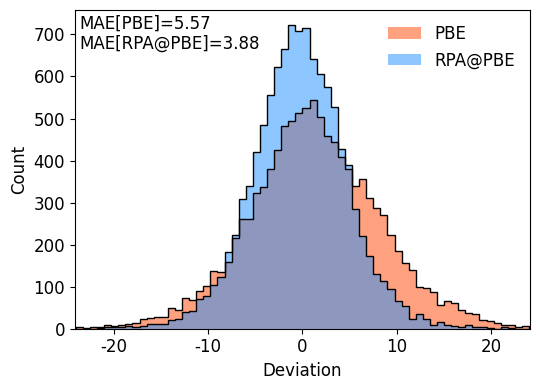

In [13]:
plot_dev_histogram(re_rpa, re_pbe, re_ref, mae_rpa, mae_pbe, "PBE", 24)

#### aug-cc-pwCVQZ orbital basis set

In [14]:
BASIS_Q = {"H":  "aug-cc-pVQZ",
           "Be": "aug-cc-pVQZ",
           "B":  "aug-cc-pwCVQZ",
           "C":  "aug-cc-pwCVQZ",
           "N":  "aug-cc-pwCVQZ",
           "O":  "aug-cc-pwCVQZ",
           "F":  "aug-cc-pwCVQZ",
           "Al": "aug-cc-pwCVQZ",
           "Si": "aug-cc-pwCVQZ",
           "P":  "aug-cc-pwCVQZ",
           "S":  "aug-cc-pwCVQZ",
           "Cl": "aug-cc-pwCVQZ"}

In [15]:
if os.path.isfile("json/W4-11_PBE_Q.json"):
    print('Reading results from W4-11_PBE_Q.json')
    with open("json/W4-11_PBE_Q.json", 'r') as file_obj:
        (etot_pbe, etot_rpa) = json.load(file_obj)
else:
    etot_pbe = dict()
    etot_rpa = dict()
    pbar = tqdm(sorted(W4_11.systems))
    for system in pbar:
        e_pbe, e_rpa = calc_one_system(W4_11.systems[system]["atoms"],
                                       W4_11.systems[system]["coords"],
                                       W4_11.systems[system]["charge"],
                                       W4_11.systems[system]["spin"],
                                       BASIS_Q,
                                       "PBE")
        etot_pbe[system] = e_pbe
        etot_rpa[system] = e_rpa
    with open('json/W4-11_PBE_Q.json', 'w', encoding='utf-8') as file_obj:
        json.dump((etot_pbe, etot_rpa), file_obj, ensure_ascii=False, indent=4)

Reading results from W4-11_PBE_Q.json


In [16]:
mae_pbe, re_pbe, re_ref = eval_ds(reactions, etot_pbe)
mae_rpa, re_rpa, re_ref = eval_ds(reactions, etot_rpa)

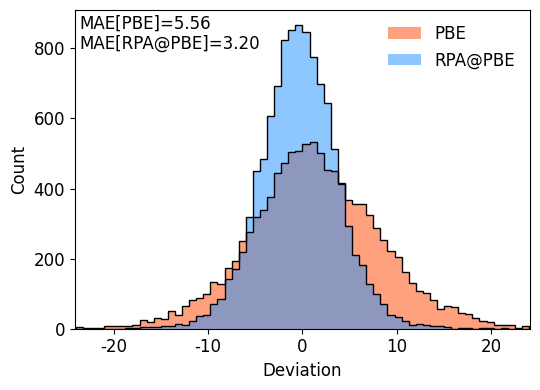

In [17]:
plot_dev_histogram(re_rpa, re_pbe, re_ref, mae_rpa, mae_pbe, "PBE", 24)

#### Complete basis set extrapolation

In [18]:
def basis_set_extrapolation(e1, e2, n1=3., n2=4):
    """Basis set extrapolation."""
    return (e1*n1**3 - e2*n2**3)/(n1**3-n2**3)

In [19]:
with open("json/W4-11_PBE_T.json", 'r') as file_obj:
    (etot_pbe_t, etot_rpa_t) = json.load(file_obj)
with open("json/W4-11_PBE_Q.json", 'r') as file_obj:
    (etot_pbe_q, etot_rpa_q) = json.load(file_obj)

In [20]:
etot_pbe_cbs = {}
etot_rpa_cbs = {}
for s in etot_rpa_t:
    etot_pbe_cbs[s] = basis_set_extrapolation(etot_pbe_t[s], etot_pbe_q[s])
    etot_rpa_cbs[s] = basis_set_extrapolation(etot_rpa_t[s], etot_rpa_q[s])

In [21]:
mae_pbe_cbs, re_pbe, re_ref = eval_ds(reactions, etot_pbe_cbs)
mae_rpa_cbs, re_rpa, re_ref = eval_ds(reactions, etot_rpa_cbs)

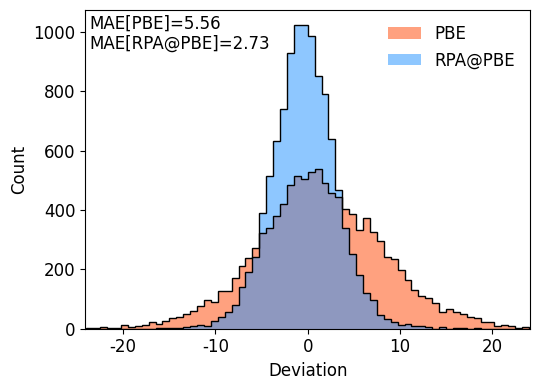

In [22]:
plot_dev_histogram(re_rpa, re_pbe, re_ref, mae_rpa_cbs, mae_pbe_cbs, "PBE", 24)

### PBE0 and RPA@PBE0

#### aug-cc-pwCVTZ orbital basis set

In [23]:
if os.path.isfile("json/W4-11_PBE0_T.json"):
    print('Reading results from W4-11_PBE0_T.json')
    with open("json/W4-11_PBE0_T.json", 'r') as file_obj:
        (etot_pbe0, etot_rpa) = json.load(file_obj)
else:
    etot_pbe0 = dict()
    etot_rpa = dict()
    pbar = tqdm(sorted(W4_11.systems))
    for system in pbar:
        e_pbe0, e_rpa = calc_one_system(W4_11.systems[system]["atoms"],
                                       W4_11.systems[system]["coords"],
                                       W4_11.systems[system]["charge"],
                                       W4_11.systems[system]["spin"],
                                       BASIS_T,
                                       "PBE0")
        etot_pbe0[system] = e_pbe0
        etot_rpa[system] = e_rpa
    with open('json/W4-11_PBE0_T.json', 'w', encoding='utf-8') as file_obj:
        json.dump((etot_pbe0, etot_rpa), file_obj, ensure_ascii=False, indent=4)

Reading results from W4-11_PBE0_T.json


In [24]:
mae_pbe0, re_pbe0, re_ref = eval_ds(reactions, etot_pbe0)
mae_rpa, re_rpa, re_ref = eval_ds(reactions, etot_rpa)

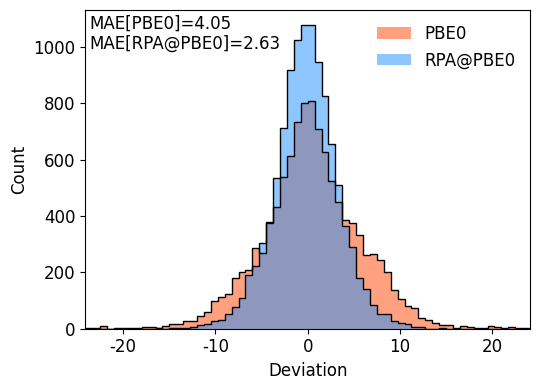

In [25]:
plot_dev_histogram(re_rpa, re_pbe0, re_ref, mae_rpa, mae_pbe0, "PBE0", 24)

#### aug-cc-pwCVQZ orbital basis set

In [26]:
if os.path.isfile("json/W4-11_PBE0_Q.json"):
    print('Reading results from W4-11_PBE0_Q.json')
    with open("json/W4-11_PBE0_Q.json", 'r') as file_obj:
        (etot_pbe0, etot_rpa) = json.load(file_obj)
else:
    etot_pbe0 = dict()
    etot_rpa = dict()
    pbar = tqdm(sorted(W4_11.systems))
    for system in pbar:
        e_pbe0, e_rpa = calc_one_system(W4_11.systems[system]["atoms"],
                                       W4_11.systems[system]["coords"],
                                       W4_11.systems[system]["charge"],
                                       W4_11.systems[system]["spin"],
                                       BASIS_Q,
                                       "PBE0")
        etot_pbe0[system] = e_pbe0
        etot_rpa[system] = e_rpa
    with open('json/W4-11_PBE0_Q.json', 'w', encoding='utf-8') as file_obj:
        json.dump((etot_pbe0, etot_rpa), file_obj, ensure_ascii=False, indent=4)

Reading results from W4-11_PBE0_Q.json


In [27]:
mae_pbe0, re_pbe0, re_ref = eval_ds(reactions, etot_pbe0)
mae_rpa, re_rpa, re_ref = eval_ds(reactions, etot_rpa)

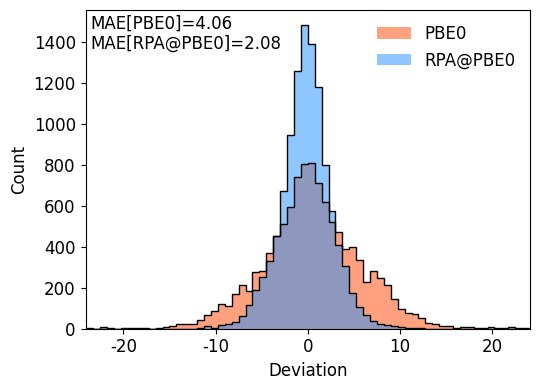

In [28]:
plot_dev_histogram(re_rpa, re_pbe0, re_ref, mae_rpa, mae_pbe0, "PBE0", 24)

#### Complete basis set extrapolation

In [29]:
with open("json/W4-11_PBE0_T.json", 'r') as file_obj:
    (etot_pbe0_t, etot_rpa_t) = json.load(file_obj)
with open("json/W4-11_PBE0_Q.json", 'r') as file_obj:
    (etot_pbe0_q, etot_rpa_q) = json.load(file_obj)

In [30]:
etot_pbe0_cbs = {}
etot_rpa_cbs = {}
for s in etot_rpa_t:
    etot_pbe0_cbs[s] = basis_set_extrapolation(etot_pbe0_t[s], etot_pbe0_q[s])
    etot_rpa_cbs[s] = basis_set_extrapolation(etot_rpa_t[s], etot_rpa_q[s])

In [31]:
mae_pbe0_cbs, re_pbe0, re_ref = eval_ds(reactions, etot_pbe0_cbs)
mae_rpa_cbs, re_rpa, re_ref = eval_ds(reactions, etot_rpa_cbs)

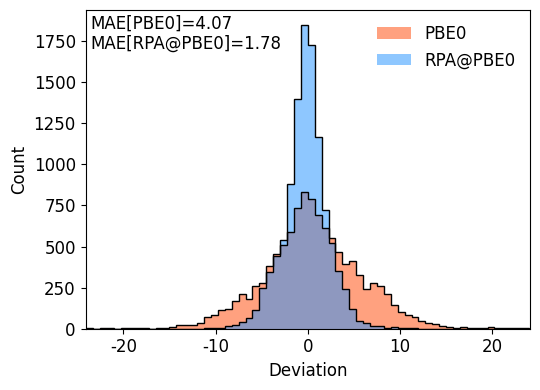

In [32]:
plot_dev_histogram(re_rpa, re_pbe0, re_ref, mae_rpa_cbs, mae_pbe0_cbs, "PBE0", 24)